In [1]:
from scripts.data_prep import get_df_filtered

df = get_df_filtered(data_path="AI_mfg_data")
df

,image_1,image_2,label_path
0,AI_mfg_data/train_images/train_image_1_1.png,AI_mfg_data/train_images/train_image_1_2.png,AI_mfg_data/gt_labels/train_image_1.mat
1,AI_mfg_data/train_images/train_image_2_1.png,AI_mfg_data/train_images/train_image_2_2.png,AI_mfg_data/gt_labels/train_image_2.mat
2,AI_mfg_data/train_images/train_image_3_1.png,AI_mfg_data/train_images/train_image_3_2.png,AI_mfg_data/gt_labels/train_image_3.mat
3,AI_mfg_data/train_images/train_image_4_1.png,AI_mfg_data/train_images/train_image_4_2.png,AI_mfg_data/gt_labels/train_image_4.mat
9,AI_mfg_data/train_images/train_image_10_1.png,AI_mfg_data/train_images/train_image_10_2.png,AI_mfg_data/gt_labels/train_image_10.mat
...,...,...,...
23995,AI_mfg_data/train_images/train_image_23996_1.png,AI_mfg_data/train_images/train_image_23996_2.png,AI_mfg_data/gt_labels/train_image_23996.mat
23996,AI_mfg_data/train_images/train_image_23997_1.png,AI_mfg_data/train_images/train_image_23997_2.png,AI_mfg_data/gt_labels/train_image_23997.mat
23997,AI_mfg_data/train_images/train_image_23998_1.png,AI_mfg_data/train_images/train_image_23998_2.png,AI_mfg_data/gt_labels/train_image_23998.mat
23998,AI_mfg_data/train_images/train_image_23999_1.png,AI_mfg_data/train_images/train_image_23999_2.png,AI_mfg_data/gt_labels/train_image_23999.mat


In [2]:
import random

random.seed(42)
random_idx = random.randint(0, len(df))

img1_path, img2_path, disp_field_path = df.iloc[random_idx]
img1_path, img2_path, disp_field_path

(PosixPath('AI_mfg_data/train_images/train_image_4255_1.png'),
 PosixPath('AI_mfg_data/train_images/train_image_4255_2.png'),
 PosixPath('AI_mfg_data/gt_labels/train_image_4255.mat'))

In [3]:
from PIL import Image
from scipy import io

img1 = Image.open(img1_path)
img2 = Image.open(img2_path)
mat_data = io.loadmat(disp_field_path)

if 'Disp_field_1' in mat_data:
    disp_field = mat_data['Disp_field_1']
elif 'Disp_field_2' in mat_data:
    disp_field = mat_data['Disp_field_2']
else:
    raise KeyError("Neither Disp_field_1 nor Disp_field_2 found in MAT file.")

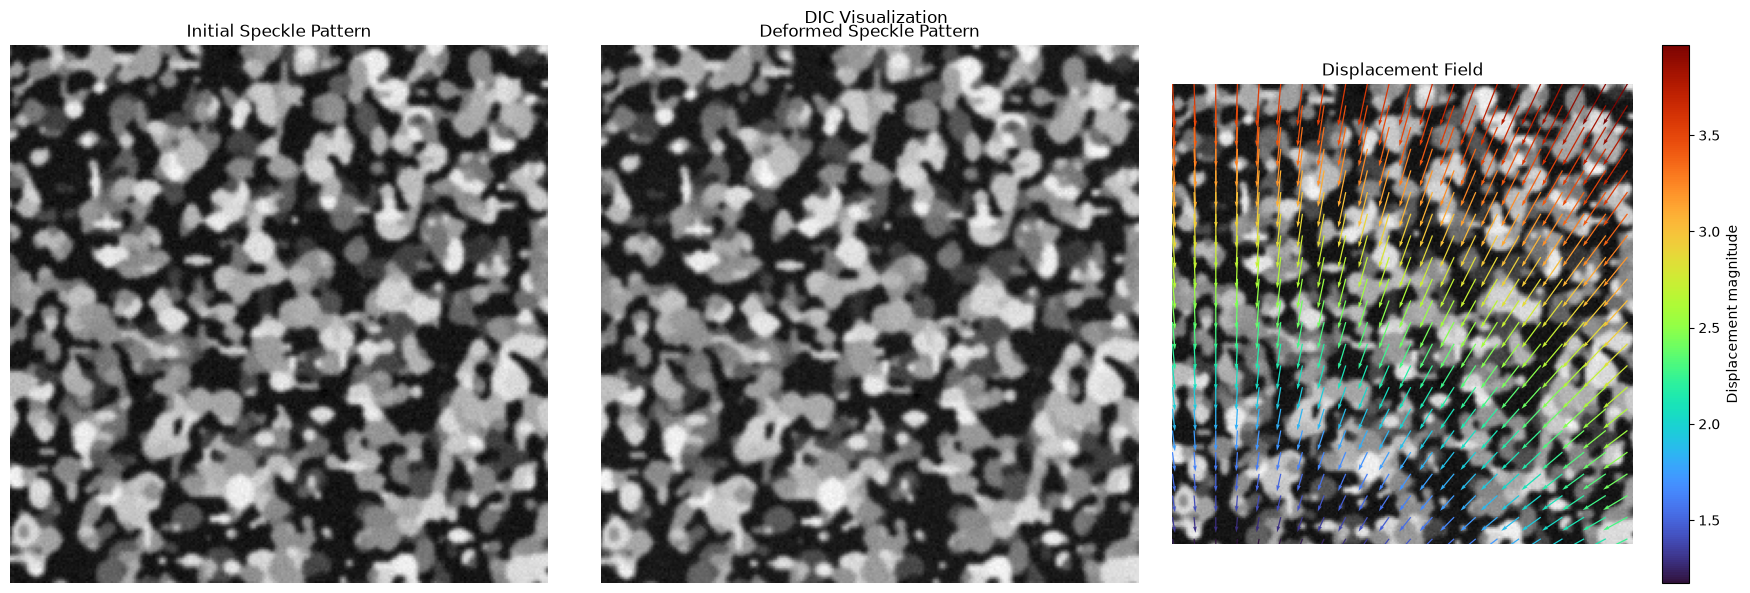

In [4]:
from scripts.plotting import visualize_dic

visualize_dic(
    initial=img1,
    deformed=img2,
    displacement=disp_field
)

In [5]:
import torch

def get_device() -> torch.device:
    if torch.cuda.is_available():
        return torch.device("cuda")
    elif torch.backends.mps.is_available():
        return torch.device("mps")

get_device()

device(type='mps')

In [6]:

import torch
from PIL import Image
from torchvision import transforms

def predict(
    model: torch.nn.Module,
    img1: Image.Image | torch.Tensor,
    img2: Image.Image | torch.Tensor,
    accelerator: bool = True
) -> torch.Tensor:

    to_tensor = transforms.ToTensor()

    if not isinstance(img1, torch.Tensor):
        img1 = to_tensor(img1)

    if not isinstance(img2, torch.Tensor):
        img2 = to_tensor(img2)

    if img1.ndim != 3 or img2.ndim != 3:
        raise ValueError(
            f"Expected images with shape [C, H, W]; "
            f"got {tuple(img1.shape)} and {tuple(img2.shape)}"
        )

    if img1.shape != img2.shape:
        raise ValueError(
            f"Input image shapes differ: "
            f"{tuple(img1.shape)} vs {tuple(img2.shape)}"
        )

    device = (
        get_device() if accelerator
        else torch.device("cpu")
    )

    model = model.to(device)
    img1 = img1.unsqueeze(0).to(device=device, dtype=torch.float32)
    img2 = img2.unsqueeze(0).to(device=device, dtype=torch.float32)

    model.eval()

    with torch.inference_mode():
        disp_field = model(img1, img2)

    if disp_field.ndim != 4 or disp_field.shape[0] != 1:
        raise ValueError(
            f"Expected output [1, 2, H, W], "
            f"got {tuple(disp_field.shape)}"
        )

    return disp_field[0].detach().cpu()


In [7]:
from models.crossflow import TransformerDIC

model = TransformerDIC()

state_dict = torch.load("models/checkpoints/crossflow.pth")
model.load_state_dict(state_dict)

/Users/kb/Documents/AI_in_mfg/models/crossflow.py:60: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.encoder = nn.TransformerEncoder(layer, num_layers=num_layers)


<All keys matched successfully>

In [8]:
disp_field_pred = predict(
    model=model,
    img1=img1,
    img2=img2,
    accelerator=False
)

disp_field_pred.shape

torch.Size([2, 256, 256])

In [9]:
import numpy as np
import torch
import matplotlib.pyplot as plt


def compare_displacement(gt, pred):

    if isinstance(gt, torch.Tensor):
        gt = gt.detach().numpy()
    if isinstance(pred, torch.Tensor):
        pred = pred.detach().numpy()

    gt = np.asarray(gt)
    pred = np.asarray(pred)

    if pred.ndim == 4:
        if pred.shape[0] != 1:
            raise ValueError("Expected prediction batch size 1.")
        pred = pred[0]

    if pred.ndim == 3 and pred.shape[0] == 2:
        pred = pred.transpose(1, 2, 0)

    if gt.shape != pred.shape or gt.ndim != 3 or gt.shape[-1] != 2:
        raise ValueError(
            f"Expected matching (H, W, 2) fields; got gt={gt.shape}, "
            f"pred={pred.shape}"
        )

    error = pred - gt

    epe = np.linalg.norm(error, axis=-1)

    metrics = {
        "Mean EPE (pixels)": float(np.mean(epe)),
        "Median EPE (pixels)": float(np.median(epe)),
        "EPE RMSE (pixels)": float(np.sqrt(np.mean(epe**2))),
        "Mean absolute ux error": float(np.mean(np.abs(error[..., 0]))),
        "Mean absolute uy error": float(np.mean(np.abs(error[..., 1]))),
        "Maximum EPE (pixels)": float(np.max(epe)),
    }

    print("\nDisplacement Comparison")
    print("-" * 35)
    for name, value in metrics.items():
        print(f"{name}: {value:.6f}")

    return metrics, epe

In [10]:
def plot_displacement_quiver(gt, pred, stride=12, arrow_scale=1.0):
    if isinstance(gt, torch.Tensor):
        gt = gt.detach().numpy()
    if isinstance(pred, torch.Tensor):
        pred = pred.detach().numpy()

    gt = np.asarray(gt)
    pred = np.asarray(pred)

    if pred.ndim == 4:
        if pred.shape[0] != 1:
            raise ValueError("Expected prediction batch size 1.")
        pred = pred[0]

    if pred.ndim == 3 and pred.shape[0] == 2:
        pred = pred.transpose(1, 2, 0)

    if gt.ndim != 3 or gt.shape[-1] != 2 or pred.shape != gt.shape:
        raise ValueError(
            f"Expected matching fields of shape (H, W, 2); "
            f"got gt={gt.shape}, pred={pred.shape}"
        )

    H, W, _ = gt.shape
    y, x = np.mgrid[0:H:stride, 0:W:stride]

    fig, axes = plt.subplots(1, 2, figsize=(14, 6))

    fields = [gt, pred]
    titles = ["Ground Truth Displacement", "Predicted Displacement"]

    for ax, field, title in zip(axes, fields, titles):
        ux = field[::stride, ::stride, 0]
        uy = field[::stride, ::stride, 1]

        magnitude = np.sqrt(ux**2 + uy**2)

        ax.quiver(
            x, y, ux, -uy,
            magnitude,
            cmap="turbo",
            angles="xy",
            scale_units="xy",
            scale=arrow_scale,
            pivot="tail",
            width=0.003,
            headwidth=4,
            headlength=5
        )

        ax.set_title(title)
        ax.set_xlim(0, W - 1)
        ax.set_ylim(H - 1, 0)
        ax.set_aspect("equal")
        ax.set_xlabel("X (pixels)")
        ax.set_ylabel("Y (pixels)")

    plt.tight_layout()
    plt.show()

In [11]:
compare_displacement(pred=disp_field_pred, gt=disp_field)


Displacement Comparison
-----------------------------------
Mean EPE (pixels): 0.517072
Median EPE (pixels): 0.467108
EPE RMSE (pixels): 0.608829
Mean absolute ux error: 0.322985
Mean absolute uy error: 0.336166
Maximum EPE (pixels): 2.687336


({'Mean EPE (pixels)': 0.5170716695856965,
  'Median EPE (pixels)': 0.46710837544369754,
  'EPE RMSE (pixels)': 0.6088286955090076,
  'Mean absolute ux error': 0.3229853989803191,
  'Mean absolute uy error': 0.3361659826889901,
  'Maximum EPE (pixels)': 2.6873360061879223},
 array([[1.68599751, 1.68212309, 1.54222758, ..., 2.41929028, 2.68257629,
         2.68733601],
        [1.67737137, 1.67347711, 1.53378082, ..., 2.41110778, 2.6744363 ,
         2.67921074],
        [1.56811945, 1.56376076, 1.42576938, ..., 2.26394207, 2.53438276,
         2.53926461],
        ...,
        [0.08174841, 0.08785278, 0.09280185, ..., 1.25085822, 1.40572152,
         1.4146175 ],
        [0.23359301, 0.23804253, 0.22402875, ..., 1.24328485, 1.38884303,
         1.39774415],
        [0.22624961, 0.23086078, 0.21773244, ..., 1.24322034, 1.38883496,
         1.3977378 ]], shape=(256, 256)))

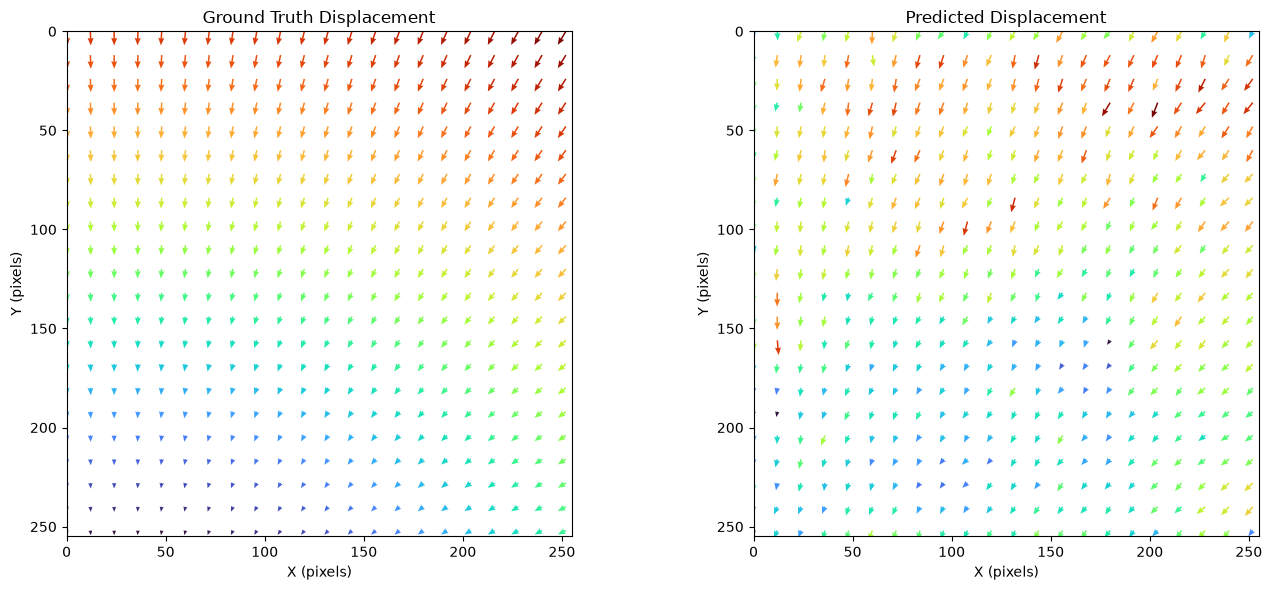

In [12]:
plot_displacement_quiver(pred=disp_field_pred, gt=disp_field, arrow_scale=0.5)

In [13]:
import numpy as np
import torch
import matplotlib.pyplot as plt


def plot_displacement_quiver(
    gt,
    pred,
    stride=12,
    arrow_scale=1.0
):

    def to_numpy(x):
        if isinstance(x, torch.Tensor):
            x = x.detach().cpu().numpy()
        return np.asarray(x)

    gt = to_numpy(gt)
    pred = to_numpy(pred)

    if pred.ndim == 4:
        if pred.shape[0] != 1:
            raise ValueError(
                "Expected prediction batch size 1, "
                f"got {pred.shape[0]}."
            )
        pred = pred[0]

    if pred.ndim == 3 and pred.shape[-1] != 2:
        if pred.shape[0] == 2:
            pred = np.transpose(pred, (1, 2, 0))

    if gt.ndim != 3 or gt.shape[-1] != 2:
        raise ValueError(
            f"Ground truth must have shape (H, W, 2), got {gt.shape}."
        )

    if pred.shape != gt.shape:
        raise ValueError(
            f"Shape mismatch: gt={gt.shape}, pred={pred.shape}."
        )

    if stride < 1:
        raise ValueError("stride must be at least 1.")

    if arrow_scale <= 0:
        raise ValueError("arrow_scale must be positive.")

    if not np.isfinite(gt).all() or not np.isfinite(pred).all():
        raise ValueError("Fields contain NaN or infinite values.")

    H, W, _ = gt.shape

    gt_mag = np.linalg.norm(gt, axis=-1)
    pred_mag = np.linalg.norm(pred, axis=-1)

    vmin = min(gt_mag.min(), pred_mag.min())
    vmax = max(gt_mag.max(), pred_mag.max())

    if np.isclose(vmin, vmax):
        vmax = vmin + 1e-6

    # Quiver grid
    y, x = np.mgrid[0:H:stride, 0:W:stride]

    fig, axes = plt.subplots(1, 2, figsize=(15, 6))

    fields = [gt, pred]
    titles = [
        "Ground Truth Displacement",
        "Predicted Displacement"
    ]

    for ax, field, title in zip(axes, fields, titles):
        ux = field[::stride, ::stride, 0]
        uy = field[::stride, ::stride, 1]

        magnitude = np.sqrt(ux**2 + uy**2)

        q = ax.quiver(
            x, y,
            ux, -uy, 
            magnitude,
            cmap="turbo",
            clim=(vmin, vmax),
            angles="xy",
            scale_units="xy",
            scale=arrow_scale,
            pivot="tail",
            width=0.003,
            headwidth=4,
            headlength=5
        )

        ax.set_title(title)
        ax.set_xlim(0, W - 1)
        ax.set_ylim(H - 1, 0)
        ax.set_aspect("equal")
        ax.set_xlabel("X (pixels)")
        ax.set_ylabel("Y (pixels)")

        fig.subplots_adjust(
            left=0.06,
            right=0.90,
            bottom=0.10,
            top=0.88,
            wspace=0.30
        )

        cbar_ax = fig.add_axes([0.92, 0.15, 0.015, 0.70])
        fig.colorbar(
            q,
            cax=cbar_ax,
            label="Displacement magnitude (pixels)"
        )
        
    fig.suptitle("Ground Truth vs Predicted Displacement")
    # plt.tight_layout()
    plt.show()

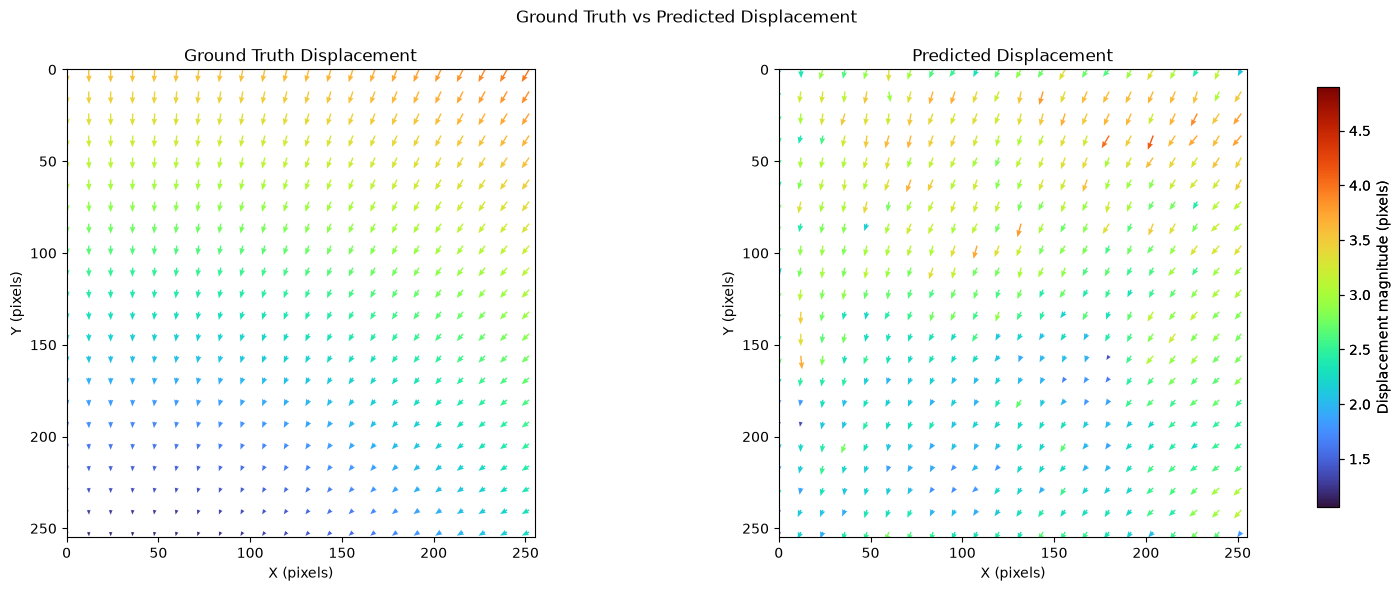

In [14]:
plot_displacement_quiver(pred=disp_field_pred, gt=disp_field, arrow_scale=0.5)

In [15]:
from pathlib import Path

models_path = Path("models/checkpoints")

model_paths = sorted([p for p in models_path.iterdir()])
model_paths

[PosixPath('models/checkpoints/crossflow.pth'),
 PosixPath('models/checkpoints/effnet_encoder_decoder.pth'),
 PosixPath('models/checkpoints/effnet_transformer.pth')]

In [16]:
from models.crossflow import TransformerDIC
from models.efficientnet_encoder_decoder import EffNetEncDec
from models.efficientnet_transformer import EffnetTranformer

models_arcs = (TransformerDIC, EffNetEncDec, EffnetTranformer)

models = [model() for model in models_arcs]

In [17]:
state_dicts = (torch.load(checkpoint, map_location="cpu") for checkpoint in model_paths)

In [18]:
for model, checkpoint in zip(models, state_dicts):
    model.load_state_dict(checkpoint)

In [19]:
import pandas as pd
from PIL import Image
from scipy import io
import random

def create_sample(
    paths_df: pd.DataFrame,
    seed: int = 42
):
    random.seed(seed)
    index = random.randint(0, len(paths_df))
    img1_path, img2_path, disp_field_path = paths_df.iloc[index]
    img1 = Image.open(img1_path)
    img2 = Image.open(img2_path)
    mat_data = io.loadmat(disp_field_path)

    if 'Disp_field_1' in mat_data:
        disp_field = mat_data['Disp_field_1']
    elif 'Disp_field_2' in mat_data:
        disp_field = mat_data['Disp_field_2']
    else:
        raise KeyError("Neither Disp_field_1 nor Disp_field_2 found in MAT file.")

    return img1, img2, disp_field

In [20]:
img1, img2, disp_field = create_sample(df)

Model: crossflow

Displacement Comparison
-----------------------------------
Mean EPE (pixels): 0.517072
Median EPE (pixels): 0.467108
EPE RMSE (pixels): 0.608829
Mean absolute ux error: 0.322985
Mean absolute uy error: 0.336166
Maximum EPE (pixels): 2.687336


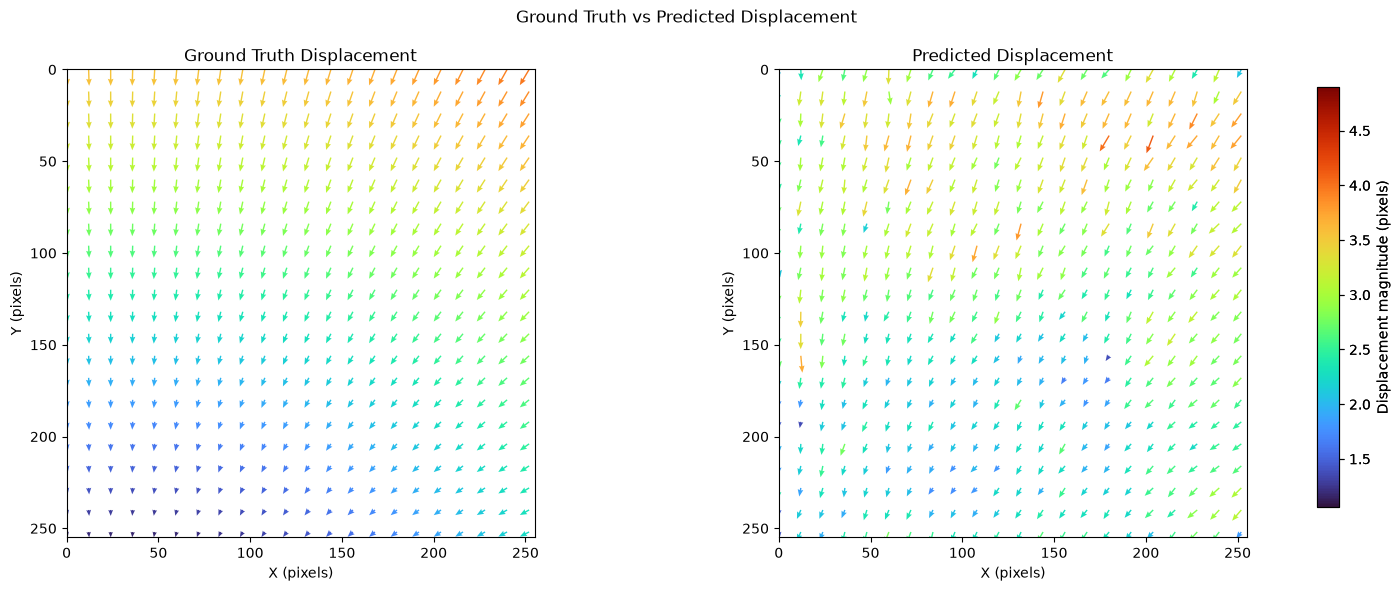

------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
Model: efficientnet_encoder_decoder

Displacement Comparison
-----------------------------------
Mean EPE (pixels): 0.085392
Median EPE (pixels): 0.078549
EPE RMSE (pixels): 0.097973
Mean absolute ux error: 0.049433
Mean absolute uy error: 0.059923
Maximum EPE (pixels): 1.559171


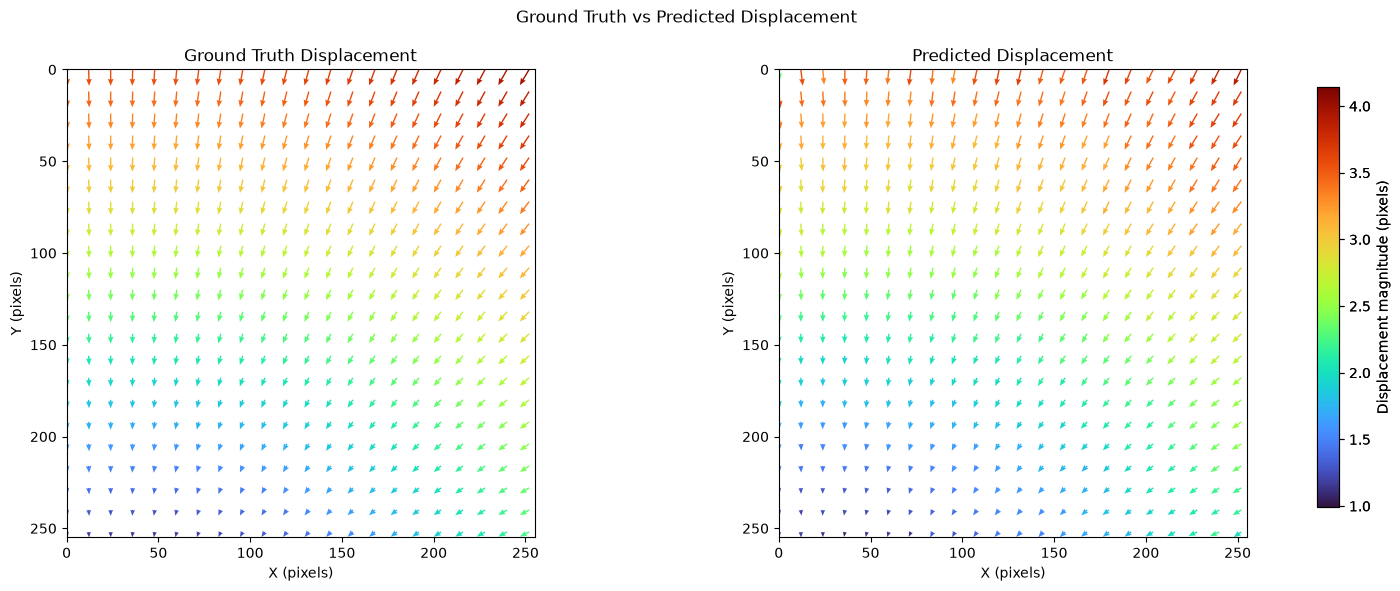

------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
Model: efficientnet_transformer

Displacement Comparison
-----------------------------------
Mean EPE (pixels): 0.082603
Median EPE (pixels): 0.074447
EPE RMSE (pixels): 0.095573
Mean absolute ux error: 0.064190
Mean absolute uy error: 0.039939
Maximum EPE (pixels): 1.220649


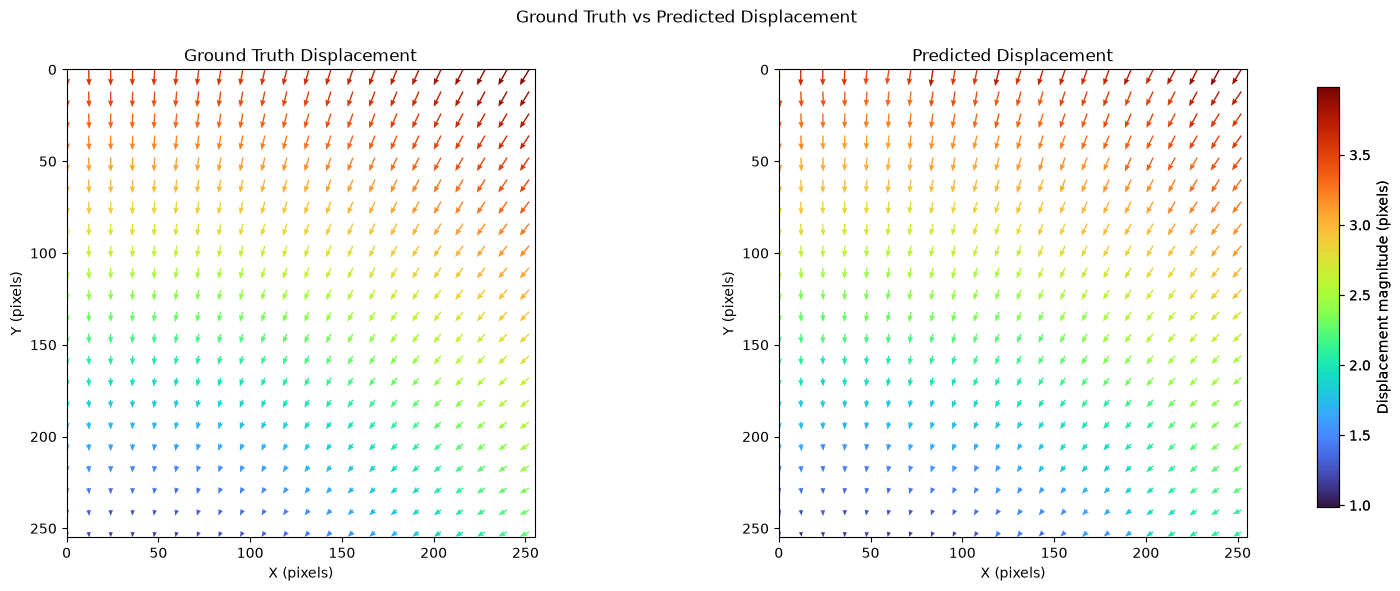

------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------


In [21]:
for model in models:
    pred = predict(
        model=model,
        img1=img1,
        img2=img2,
        accelerator=False
    )
    print(f"Model: {model.name}")

    compare_displacement(gt=disp_field, pred=pred)

    plot_displacement_quiver(pred=pred, gt=disp_field, arrow_scale=0.4)
    print("---" * 100)

In [22]:
print("GT shape:", np.asarray(disp_field).shape)
print("GT range:", np.min(disp_field), np.max(disp_field))

for model in models:
    pred = predict(
        model=model,
        img1=img1,
        img2=img2,
        accelerator=False
    )

    pred_np = pred.detach().cpu().numpy() if isinstance(pred, torch.Tensor) else np.asarray(pred)

    print(f"\nModel: {model.name}")
    print("Prediction shape:", pred_np.shape)
    print("Prediction range:", pred_np.min(), pred_np.max())
    print("Prediction mean:", pred_np.mean())
    print("Prediction std:", pred_np.std())

    compare_displacement(gt=disp_field, pred=pred)

GT shape: (256, 256, 2)
GT range: -3.574773474518707 0.22668513647163077

Model: crossflow
Prediction shape: (2, 256, 256)
Prediction range: -4.421977 0.47560352
Prediction mean: -1.7785882
Prediction std: 0.8777783

Displacement Comparison
-----------------------------------
Mean EPE (pixels): 0.517072
Median EPE (pixels): 0.467108
EPE RMSE (pixels): 0.608829
Mean absolute ux error: 0.322985
Mean absolute uy error: 0.336166
Maximum EPE (pixels): 2.687336

Model: efficientnet_encoder_decoder
Prediction shape: (2, 256, 256)
Prediction range: -3.6942506 0.5272909
Prediction mean: -1.5507387
Prediction std: 0.93726355

Displacement Comparison
-----------------------------------
Mean EPE (pixels): 0.085392
Median EPE (pixels): 0.078549
EPE RMSE (pixels): 0.097973
Mean absolute ux error: 0.049433
Mean absolute uy error: 0.059923
Maximum EPE (pixels): 1.559171

Model: efficientnet_transformer
Prediction shape: (2, 256, 256)
Prediction range: -3.7363276 0.42145637
Prediction mean: -1.5451765
